In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import optax
from jax import jit, random
import flax.linen as nn
from flax.training import train_state
from flax import serialization
from pathlib import Path
import json

In [2]:
data_dir = Path("./data/cavity/bc")
case_dirs = sorted(data_dir.glob("case*"), key=lambda p: int(p.name[4:]))
print(f"Number of CFD cases: {len(case_dirs)}")
print(f"First case: {case_dirs[0]}")
print(f"Files: {list(case_dirs[0].iterdir())}")

Number of CFD cases: 50
First case: data\cavity\bc\case0000
Files: [WindowsPath('data/cavity/bc/case0000/case.json'), WindowsPath('data/cavity/bc/case0000/u'), WindowsPath('data/cavity/bc/case0000/u.npy'), WindowsPath('data/cavity/bc/case0000/u.png'), WindowsPath('data/cavity/bc/case0000/v'), WindowsPath('data/cavity/bc/case0000/v.npy'), WindowsPath('data/cavity/bc/case0000/v.png')]


In [3]:
def load_case(case_dir):
    with open(case_dir / "case.json", "r") as f:
        params = json.load(f)

    u = np.load(case_dir / "u.npy").astype(np.float32)
    v = np.load(case_dir / "v.npy").astype(np.float32)
    return u, v, params

u, v, params = load_case(case_dirs[0])
print(f"u shape: {u.shape}")
print(f"v shape: {v.shape}")
print("\nPhysical parameters:")
for key, value in params.items():
    print(key, ":", value)

u shape: (10, 64, 64)
v shape: (10, 64, 64)

Physical parameters:
height : 0.01
width : 0.01
vel_top : 1
density : 1
viscosity : 1e-05
rotated : False


In [4]:
# check what varies across the dataset
all_params = []
for case_dir in case_dirs:
    with open(case_dir / "case.json", "r") as f:
        all_params.append(json.load(f))

keys = ["vel_top", "density", "viscosity", "height", "width"]

for key in keys:
    values = np.array([p[key] for p in all_params])
    print(f"{key:12s}: "
          f"min = {values.min():.6g}, "
          f"max = {values.max():.6g}, "
          f"unique = {len(np.unique(values))}")

vel_top     : min = 1, max = 50, unique = 50
density     : min = 1, max = 1, unique = 1
viscosity   : min = 1e-05, max = 1e-05, unique = 1
height      : min = 0.01, max = 0.01, unique = 1
width       : min = 0.01, max = 0.01, unique = 1


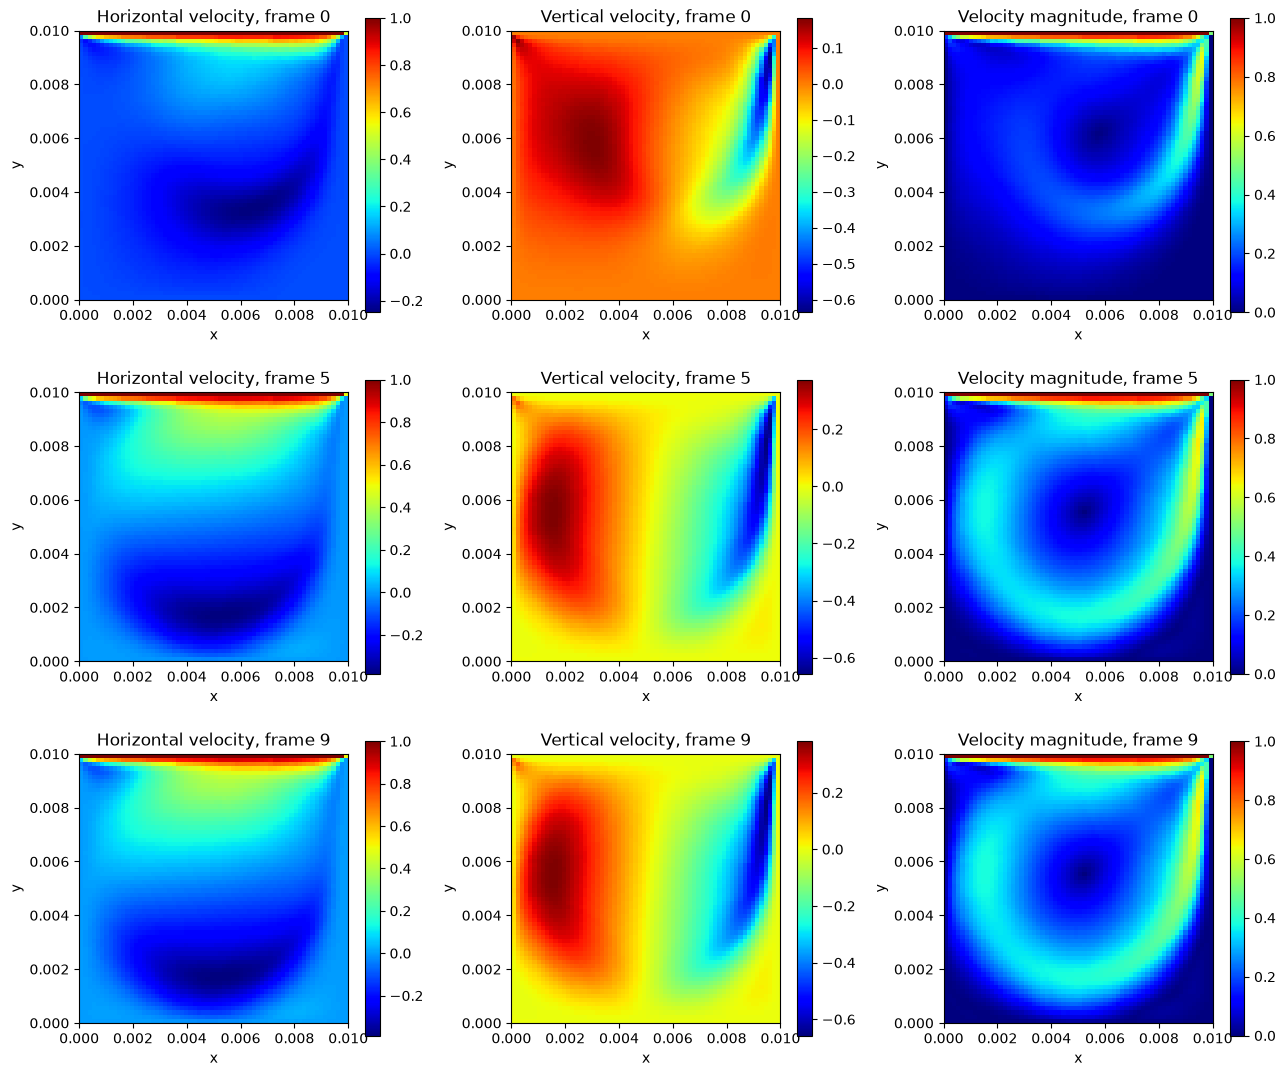

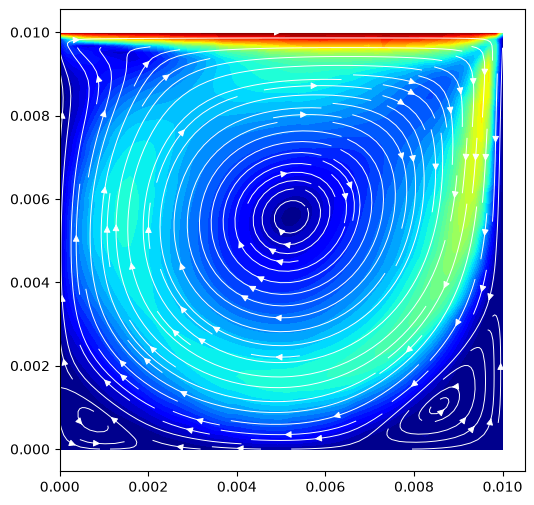

In [5]:
# visualize the CFD results for 1st case
nt, ny, nx = u.shape
frames = [0, nt // 2, nt-1]
fig, axes = plt.subplots(3, 3, figsize=(13,11))
for i, t in enumerate(frames):
    velocity_mag = np.sqrt(u[t]**2 + v[t]**2)
    fields = [u[t], v[t], velocity_mag]
    titles = [
        "Horizontal velocity",
        "Vertical velocity",
        "Velocity magnitude"
    ]
    for j in range(3):
        im = axes[i,j].imshow(
            fields[j],
            origin='lower',
            cmap='jet',
            extent=[0, params['width'],
                    0, params['height']]
        )
        axes[i,j].set_title(
            f"{titles[j]}, frame {t}"
        )
        axes[i,j].set_xlabel("x")
        axes[i,j].set_ylabel("y")
        fig.colorbar(im, ax=axes[i,j])
plt.tight_layout()
plt.show()

# streamline
x = np.linspace(0, params['width'], nx); y = np.linspace(0, params['height'], ny)
X, Y = np.meshgrid(x, y)
t = nt - 1
velocity_mag = np.sqrt(u[t]**2 + v[t]**2)
fig, ax = plt.subplots(figsize=(6,6))
im = ax.contourf(
    X,Y,velocity_mag,
    levels=40, cmap='jet'
)
ax.streamplot(
    x,y, u[t], v[t],
    color = 'white',
    density=1.5,
    linewidth=0.7        
)

In [6]:
in_channels = 5
out_channels = 2
width = 20
modes1 = 12
modes2 = 12
n_layers = 4
batch_size = 8
learning_rate = 0.001
n_epochs = 100
t_step = 1
key = random.PRNGKey(42)
rng = np.random.default_rng(42)

In [7]:
case_dirs = sorted(data_dir.glob("case*"))
rng = np.random.default_rng(42)
rng.shuffle(case_dirs)
n_cases = len(case_dirs)
n_train = int(0.8*n_cases)
n_val = int(0.1*n_cases)

train_cases, val_cases, test_cases = case_dirs[:n_train], case_dirs[n_train:n_train+n_val], case_dirs[n_train+n_val:]

def prepare_dataset(cases, step=t_step):
    inputs = []
    targets = []
    for case in cases:
        u = np.load(case / "u.npy").astype(np.float32)
        v = np.load(case / "v.npy").astype(np.float32)
        with open(case / "case.json") as f:
            properties = json.load(f)

        nt, ny, nx = u.shape
        if nt <= step:
            continue
        velocity = np.stack([u,v], axis = -1)
        x = np.linspace(0, 1, nx, dtype=np.float32)
        y = np.linspace(0, 1, ny, dtype=np.float32)
        X, Y = np.meshgrid(x, y)
        lid = properties['vel_top'] / 50 -0.5

        lid_field = np.full((ny,nx), lid, dtype=np.float32)
        conditions = np.stack([lid_field, X, Y], axis = -1)
        conditions = np.broadcast_to(conditions, (nt-step, ny, nx, 3))

        input_fields = np.concatenate(
            [velocity[:-step], conditions], axis=-1
        )
        target_fields = velocity[step:]
        inputs.append(input_fields)
        targets.append(target_fields)

    return (np.concatenate(inputs, axis=0), np.concatenate(targets, axis=0))

X_train, Y_train = prepare_dataset(train_cases)
X_val, Y_val = prepare_dataset(val_cases)
X_test, Y_test = prepare_dataset(test_cases)
print(f"Training data: {X_train.shape}, {Y_train.shape}. Validation data: {X_val.shape}, {Y_val.shape}. Testing data: {X_test.shape}, {Y_test.shape}.")

velocity_mean = X_train[..., :2].mean(axis=(0,1,2), keepdims=True)
velocity_std = np.maximum(X_train[..., :2].std(axis=(0,1,2), keepdims=True), 1e-8)
for X in [X_train, X_val, X_test]:
    X[..., :2] = (X[..., :2] - velocity_mean) / velocity_std
for Y in [Y_train, Y_val, Y_test]:
    Y[...] = (Y - velocity_mean) / velocity_std

def denormalize_velocity(velocity):
    return velocity*velocity_std + velocity_mean

Training data: (3663, 64, 64, 5), (3663, 64, 64, 2). Validation data: (1066, 64, 64, 5), (1066, 64, 64, 2). Testing data: (285, 64, 64, 5), (285, 64, 64, 2).


In [8]:
class SpectralConv2d(nn.Module):
    out_channels: int
    modes1: int
    modes2: int
    @nn.compact
    def __call__(self, x):
        batch, ny, nx, in_channels = x.shape

        shape = (self.modes1, self.modes2, in_channels, self.out_channels)
        scale = 1.0 / (in_channels * self.out_channels)
        initializer = nn.initializers.normal(stddev=scale)

        R1_real = self.param("R1_real", initializer, shape)
        R1_image = self.param("R1_imag", initializer, shape)
        R2_real = self.param("R2_real", initializer, shape)
        R2_image = self.param("R2_imag", initializer, shape)

        R1 = R1_real + 1j * R1_image
        R2 = R2_real + 1j * R2_image

        # forward fourier transform
        x_hat = jnp.fft.rfft2(x, axes=(1,2))

        # initialize output fourier coefficients
        out_hat = jnp.zeros((batch, ny, nx //2 + 1, self.out_channels), dtype=x_hat.dtype)
        # nonnegative vertical frequency block
        out1 = jnp.einsum(
            "byxi,yxio->byxo",
            x_hat[:, :self.modes1, :self.modes2, :],
            R1
        )
        # negative vertical frequency block
        out2 = jnp.einsum(
            "byxi, yxio->byxo",
            x_hat[:, -self.modes1:, :self.modes2, :],
            R1
        )

        out_hat = out_hat.at[:, :self.modes1, :self.modes2, :].set(out1)
        out_hat = out_hat.at[:, -self.modes1:, :self.modes2, :].set(out2)

        # inverse fourier transform
        z = jnp.fft.irfft2(out_hat, s=(ny,nx), axes=(1,2))
        return z

In [9]:
class FourierBlock(nn.Module):
    width: int
    modes1: int
    modes2: int
    @nn.compact
    def __call__(self, x):
        # Global spectral transformation
        spectral = SpectralConv2d(
            out_channels = self.width,
            modes1 = self.modes1,
            modes2 = self.modes2
        )(x)
        # local linear transformation
        local = nn.Dense(self.width)(x)
        x = nn.gelu(spectral + local)
        return x

In [10]:
class FNO2d(nn.Module):
    width: int = 20
    modes1: int = 12
    modes2: int = 12
    n_layers: int = 4
    out_channels: int = 2

    @nn.compact
    def __call__(self, x):
        # Lifting 5-> 20
        x = nn.Dense(self.width, name="lifting")(x)

        # fourier layers 20 -> 20
        for i in range(self.n_layers):
            x = FourierBlock(
                width=self.width,
                modes1=self.modes1,
                modes2=self.modes2,
                name=f"fourier_block_{i}"
            )(x)

        # project 20 -> 128
        x = nn.Dense(128, name='projection1')(x)
        x = nn.gelu(x)

        # projection 128 -> 2
        x = nn.Dense(self.out_channels, name='projection2')(x)
        return x

In [11]:
model = FNO2d(
    width = width,
    modes1 = modes1,
    modes2 = modes2,
    n_layers = n_layers,
    out_channels = out_channels
)

X_batch = jnp.asarray(X_train[:batch_size])
Y_batch = jnp.asarray(Y_train[:batch_size])

variable = model.init(key, X_batch)
params = variable["params"]

optimizer = optax.adam(learning_rate)

state = train_state.TrainState.create(
    apply_fn=model.apply,
    params = params,
    tx = optimizer
)

In [12]:
def compute_loss(params, X, Y):
    prediction = model.apply(
        {"params": params}, X
    )
    loss = jnp.mean((prediction - Y)**2)
    return loss

@jit
def train_step(state, X, Y):
    loss, grads = jax.value_and_grad(
        compute_loss
    )(state.params, X, Y)
    state = state.apply_gradients(grads = grads)
    return state, loss
    
@jit
def eval_step(params, X, Y):
    return compute_loss(params, X, Y)

In [13]:
train_losses = []
val_losses = []

best_val_loss = np.inf
best_state = state

n_samples = len(X_train)

for epoch in range(n_epochs):
    # shuffle training samples
    indices = rng.permutation(n_samples)
    epoch_loss = 0.0
    n_seen = 0 
    # training 
    for start in range(0, n_samples, batch_size):
        idx = indices[start: start+batch_size]
        X_batch = jnp.asarray(X_train[idx])
        Y_batch = jnp.asarray(Y_train[idx])
        state, loss = train_step(
            state, X_batch, Y_batch
        )
        epoch_loss += float(loss) * len(idx)
        n_seen += len(idx)
    train_loss = epoch_loss / n_seen

    # validation
    val_loss = 0.0
    for start in range(0, len(X_val), batch_size):
        X_batch = jnp.asarray(X_val[start: start+batch_size])
        Y_batch = jnp.asarray(Y_val[start: start+batch_size])
        loss = eval_step(state.params, X_batch, Y_batch)
        val_loss += float(loss) * len(X_batch)

    val_loss = val_loss / len(X_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = state

    print(
        f"Epoch {epoch+1:3d}/{n_epochs} | "
        f"Train: {train_loss:.6e} | "
        f"Val: {val_loss:.6e}."
    )
state = best_state

save_dir = Path('results')
with open(save_dir / 'fno_state.msgpack', 'wb') as f:
    f.write(serialization.to_bytes(state))
print("Training state saved!")

Epoch   1/100 | Train: 3.521292e-02 | Val: 7.417040e-04.
Epoch   2/100 | Train: 1.105495e-03 | Val: 7.287152e-04.
Epoch   3/100 | Train: 9.383289e-04 | Val: 6.162678e-04.
Epoch   4/100 | Train: 8.314129e-04 | Val: 5.062519e-04.
Epoch   5/100 | Train: 7.803953e-04 | Val: 4.422438e-04.
Epoch   6/100 | Train: 7.588632e-04 | Val: 4.924237e-04.
Epoch   7/100 | Train: 6.942210e-04 | Val: 3.868083e-04.
Epoch   8/100 | Train: 6.736450e-04 | Val: 3.748192e-04.
Epoch   9/100 | Train: 5.873651e-04 | Val: 6.258861e-04.
Epoch  10/100 | Train: 5.964855e-04 | Val: 5.171297e-04.
Epoch  11/100 | Train: 5.383039e-04 | Val: 2.871284e-04.
Epoch  12/100 | Train: 5.050671e-04 | Val: 3.256374e-04.
Epoch  13/100 | Train: 5.056868e-04 | Val: 8.126396e-04.
Epoch  14/100 | Train: 5.219399e-04 | Val: 2.547282e-04.
Epoch  15/100 | Train: 4.690434e-04 | Val: 5.220920e-04.
Epoch  16/100 | Train: 4.666617e-04 | Val: 2.883541e-04.
Epoch  17/100 | Train: 4.368221e-04 | Val: 6.247008e-04.
Epoch  18/100 | Train: 4.307553

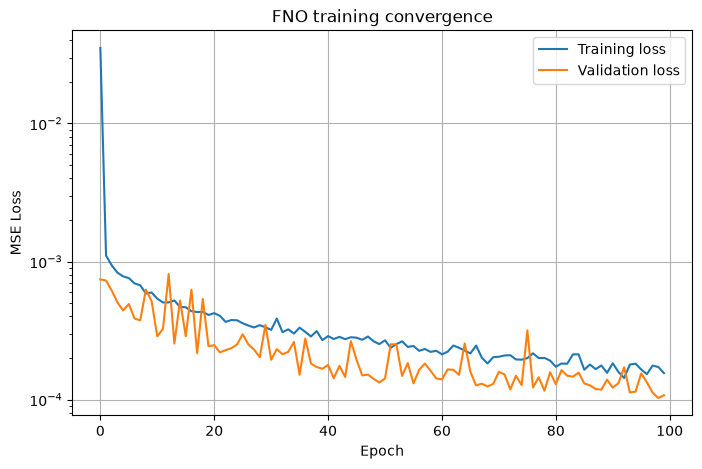

In [15]:
plt.figure(figsize=(8,5))
plt.semilogy(train_losses, label="Training loss")
plt.semilogy(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("FNO training convergence")
plt.grid()
plt.legend()
plt.show()

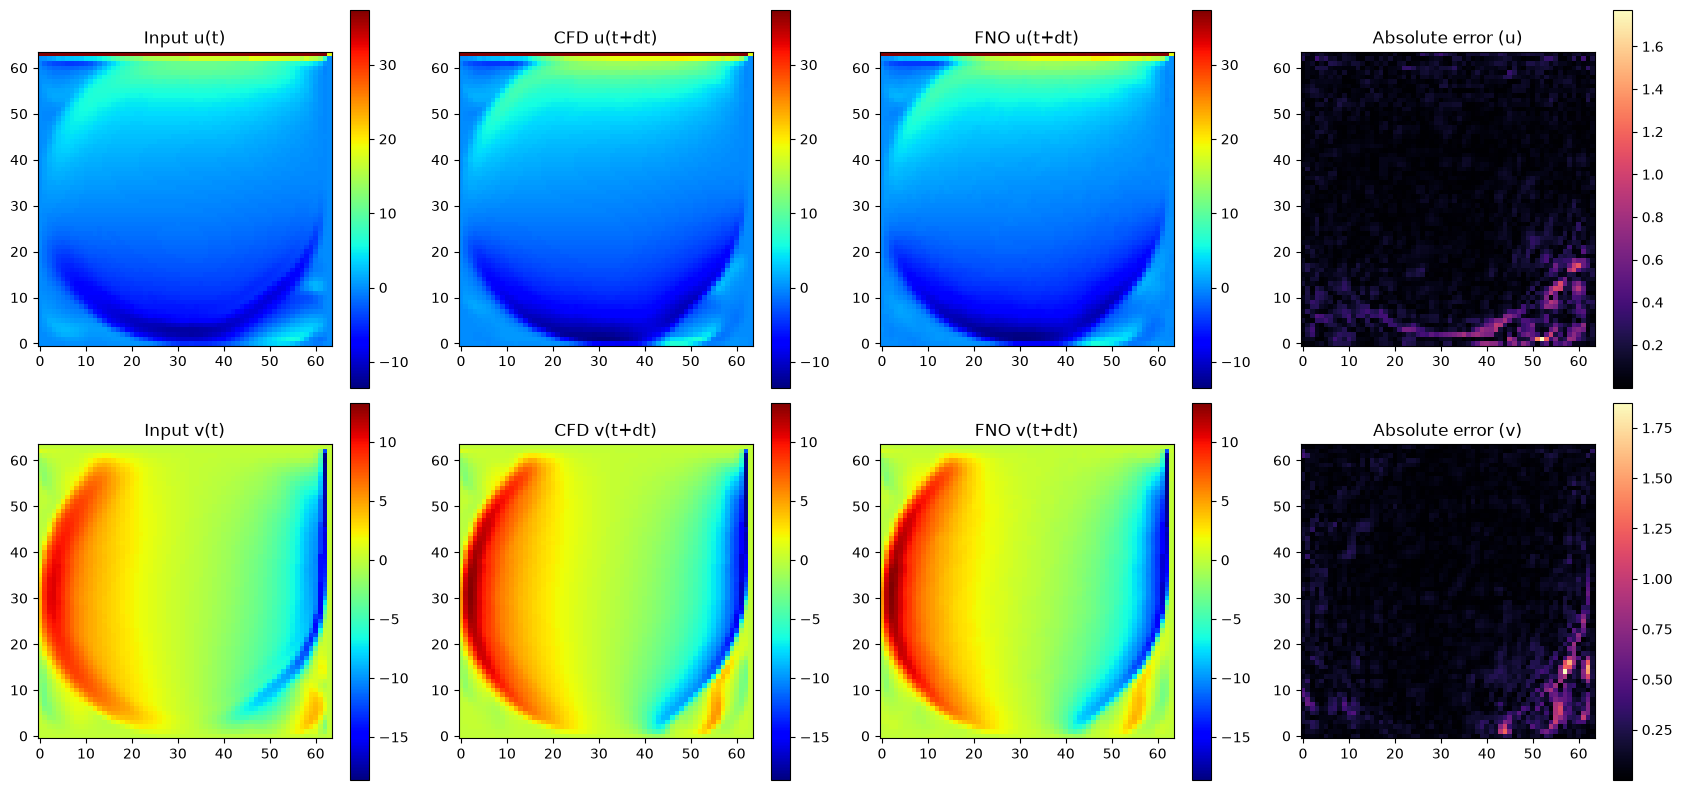

In [19]:
sample_id = 0 
X_sample = jnp.asarray(X_test[sample_id:sample_id+1])
prediction = model.apply(
    {"params": state.params},
    X_sample
)
prediction = denormalize_velocity(np.asarray(prediction))[0]
target = denormalize_velocity(Y_test[sample_id:sample_id+1])[0]
current = denormalize_velocity(X_test[sample_id:sample_id+1,..., :2])[0]

fig, axes = plt.subplots(2, 4, figsize=(17,8))

for c, name in enumerate(['u', 'v']):
    vmin = min(current[..., c].min(), target[..., c].min(), prediction[..., c].min())
    vmax = max(current[..., c].max(), target[..., c].max(), prediction[..., c].max())
    fields = [current[..., c], target[..., c], prediction[..., c], np.abs(prediction[..., c] - target[..., c])]
    titles = [f"Input {name}(t)", f"CFD {name}(t+dt)", f"FNO {name}(t+dt)", f"Absolute error ({name})"]

    for j in range(4):
        if j < 3:
            im = axes[c,j].imshow(
                fields[j],
                origin='lower',
                cmap='jet',
                vmin=vmin,
                vmax=vmax
            )
        else:
            im = axes[c,j].imshow(
                fields[j],
                origin='lower',
                cmap='magma'
            )
        axes[c,j].set_title(titles[j])
        fig.colorbar(im, ax = axes[c,j])
plt.tight_layout()
plt.show()